# Projekt 2: Credit Score Classification - MLP w PyTorch

**Cel:** zbudować i ocenić sieć neuronową MLP dla wieloklasowej klasyfikacji wiarygodności kredytowej klienta. Zmienną docelową jest `Credit_Score`, która ma trzy klasy: `Poor`, `Standard` i `Good`.

Notebook używa danych z Kaggle: [Credit Score Classification](https://www.kaggle.com/datasets/parisrohan/credit-score-classification). Kod jest po angielsku, a opis metodologii po polsku.


## Plan eksperymentu

1. Wczytanie `train.csv` i `test.csv` oraz kontrola struktury danych.
2. Wyjaśnienie roli kagglowego `test.csv`: plik nie ma `Credit_Score`, więc służy tylko do predykcji, a nie do liczenia metryk.
3. Podział oznaczonego `train.csv` na train/validation/test z kontrolą wycieku danych przez `Customer_ID`.
4. Czyszczenie danych: konwersja kolumn liczbowych zapisanych jako tekst, parsowanie `Credit_History_Age`, obsługa wartości śmieciowych i nierealnych.
5. Preprocessing fitowany wyłącznie na train: imputacja, one-hot encoding, multi-hot encoding `Type_of_Loan`, skalowanie numeryczne.
6. Trening MLP w PyTorch z `BatchNorm1d`, `Dropout`, `AdamW`, `ReduceLROnPlateau`, early stopping i class weights.
7. Systematyczna siatka hiperparametrów oraz wybór baseline i tuned modelu.
8. Random Forest jako model referencyjny.
9. Ewaluacja na wydzielonym teście z `train.csv` oraz predykcje dla nieetykietowanego `test.csv`.
10. Wnioski na podstawie faktycznie uzyskanych wyników.


In [1]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import random
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import chi2_contingency
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
DATA_DIR = Path("Credit score classification dataset")
TRAIN_PATH = DATA_DIR / "train.csv"
KAGGLE_TEST_PATH = DATA_DIR / "test.csv"
PREDICTION_OUTPUT_PATH = Path("credit_score_test_predictions.csv")

TARGET_COL = "Credit_Score"
GROUP_COL = "Customer_ID"
ID_COL = "ID"
LABEL_ORDER = ["Poor", "Standard", "Good"]
LABEL_TO_ID = {label: idx for idx, label in enumerate(LABEL_ORDER)}
ID_TO_LABEL = {idx: label for label, idx in LABEL_TO_ID.items()}

def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()

def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

device = get_device()
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


## 1. Dane

Zbiór ma dwie części. `train.csv` zawiera etykietę `Credit_Score`, dlatego służy do trenowania, walidacji i końcowej ewaluacji. `test.csv` nie zawiera etykiety, więc nie można na nim policzyć metryk takich jak accuracy, F1, `classification_report` ani macierz pomyłek. Zostanie użyty dopiero na końcu do demonstracji predykcji na nowych, nieetykietowanych danych.


In [2]:
raw_train = pd.read_csv(TRAIN_PATH, low_memory=False)
kaggle_test = pd.read_csv(KAGGLE_TEST_PATH, low_memory=False)

print(f"train.csv shape: {raw_train.shape}")
print(f"test.csv shape:  {kaggle_test.shape}")
print(f"Target in train.csv: {TARGET_COL in raw_train.columns}")
print(f"Target in test.csv:  {TARGET_COL in kaggle_test.columns}")

class_distribution = raw_train[TARGET_COL].value_counts().reindex(LABEL_ORDER)
class_distribution_pct = raw_train[TARGET_COL].value_counts(normalize=True).reindex(LABEL_ORDER) * 100
pd.DataFrame({"count": class_distribution, "percent": class_distribution_pct.round(2)})


train.csv shape: (100000, 28)
test.csv shape:  (50000, 27)
Target in train.csv: True
Target in test.csv:  False


,count,percent
Credit_Score,,
Poor,28998,29.00
Standard,53174,53.17
Good,17828,17.83


In [3]:
print(f"Unique customers in train.csv: {raw_train[GROUP_COL].nunique():,}")
print("Rows per customer:")
display(raw_train.groupby(GROUP_COL).size().describe().to_frame("rows"))

categorical_preview_cols = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Type_of_Loan"]
for col in categorical_preview_cols:
    print(f"\n{col}")
    display(raw_train[col].value_counts(dropna=False).head(10).to_frame("count"))


Unique customers in train.csv: 12,500
Rows per customer:


,rows
count,12500.0
mean,8.0
std,0.0
min,8.0
25%,8.0
50%,8.0
75%,8.0
max,8.0



Occupation


,count
Occupation,
_______,7062
Lawyer,6575
Architect,6355
Engineer,6350
Scientist,6299
Mechanic,6291
Accountant,6271
Developer,6235
Media_Manager,6232



Credit_Mix


...

,count
Payment_of_Min_Amount,
Yes,52326
No,35667
NM,12007



Payment_Behaviour


,count
Payment_Behaviour,
Low_spent_Small_value_payments,25513
High_spent_Medium_value_payments,17540
Low_spent_Medium_value_payments,13861
High_spent_Large_value_payments,13721
High_spent_Small_value_payments,11340
Low_spent_Large_value_payments,10425
!@9#%8,7600



Type_of_Loan


,count
Type_of_Loan,
NaN,11408
Not Specified,1408
Credit-Builder Loan,1280
Personal Loan,1272
Debt Consolidation Loan,1264
Student Loan,1240
Payday Loan,1200
Mortgage Loan,1176
Auto Loan,1152


### 1.1 Słownik i sens biznesowy atrybutów

Poniższa tabela porządkuje cechy z punktu widzenia modelowania. Nie wszystkie kolumny powinny trafić do modelu: identyfikatory służą do kontroli danych albo prywatności, a nie do predykcji oceny kredytowej.


In [4]:
feature_dictionary = pd.DataFrame([
    {"column": "ID", "type": "identifier", "business_meaning": "Technical row identifier.", "modeling_decision": "Drop before modeling."},
    {"column": "Customer_ID", "type": "identifier/group", "business_meaning": "Customer identifier; one customer has several monthly records.", "modeling_decision": "Use only for group split, then drop."},
    {"column": "Month", "type": "identifier/time label", "business_meaning": "Month of the monthly credit report.", "modeling_decision": "Drop from final model to focus on customer financial behavior."},
    {"column": "Name", "type": "identifier", "business_meaning": "Customer name.", "modeling_decision": "Drop for privacy/leakage reasons."},
    {"column": "SSN", "type": "identifier", "business_meaning": "Social security number.", "modeling_decision": "Drop for privacy/leakage reasons."},
    {"column": "Age", "type": "numeric", "business_meaning": "Customer age; impossible values indicate data quality issues.", "modeling_decision": "Clean, cap unrealistic values to NaN, impute median."},
    {"column": "Occupation", "type": "categorical", "business_meaning": "Customer occupation; can proxy income stability and risk profile.", "modeling_decision": "Mode imputation + one-hot encoding."},
    {"column": "Annual_Income", "type": "numeric", "business_meaning": "Annual income; higher income usually improves repayment capacity.", "modeling_decision": "Clean text artifacts, handle outliers, scale."},
    {"column": "Monthly_Inhand_Salary", "type": "numeric", "business_meaning": "Monthly net salary available to the customer.", "modeling_decision": "Median imputation + scaling."},
    {"column": "Num_Bank_Accounts", "type": "numeric", "business_meaning": "Number of bank accounts; extreme values are likely data errors.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Num_Credit_Card", "type": "numeric", "business_meaning": "Number of credit cards; can reflect credit exposure.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Interest_Rate", "type": "numeric", "business_meaning": "Credit interest rate; high values often reflect higher risk.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Num_of_Loan", "type": "numeric", "business_meaning": "Number of active loans.", "modeling_decision": "Clean text artifacts, handle outliers, scale."},
    {"column": "Type_of_Loan", "type": "multi-label categorical", "business_meaning": "Set of loan types held by the customer.", "modeling_decision": "Multi-hot encoding with train-only vocabulary."},
    {"column": "Delay_from_due_date", "type": "numeric", "business_meaning": "Payment delay in days; negative values can mean early payment.", "modeling_decision": "Allow realistic negatives, scale."},
    {"column": "Num_of_Delayed_Payment", "type": "numeric", "business_meaning": "Number of delayed payments; direct signal of repayment behavior.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Changed_Credit_Limit", "type": "numeric", "business_meaning": "Percentage change in credit limit.", "modeling_decision": "Clean text artifacts, handle outliers, scale."},
    {"column": "Num_Credit_Inquiries", "type": "numeric", "business_meaning": "Number of credit inquiries; many inquiries can indicate credit seeking.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Credit_Mix", "type": "ordinal categorical", "business_meaning": "Credit mix quality: Bad, Standard, Good.", "modeling_decision": "OHE in final pipeline; ordinal variant tested separately."},
    {"column": "Outstanding_Debt", "type": "numeric", "business_meaning": "Outstanding debt; high debt can worsen credit score.", "modeling_decision": "Clean text artifacts, scale."},
    {"column": "Credit_Utilization_Ratio", "type": "numeric", "business_meaning": "Percentage of available credit currently used.", "modeling_decision": "Scale as numeric feature."},
    {"column": "Credit_History_Age", "type": "numeric from text", "business_meaning": "Age of credit history; longer history can stabilize assessment.", "modeling_decision": "Parse text to months, impute median, scale."},
    {"column": "Payment_of_Min_Amount", "type": "categorical", "business_meaning": "Whether the customer pays only the minimum amount.", "modeling_decision": "Mode imputation + one-hot encoding."},
    {"column": "Total_EMI_per_month", "type": "numeric", "business_meaning": "Total monthly installment burden.", "modeling_decision": "Domain outlier handling + scaling."},
    {"column": "Amount_invested_monthly", "type": "numeric", "business_meaning": "Monthly invested amount; part of financial behavior.", "modeling_decision": "Median imputation + scaling."},
    {"column": "Payment_Behaviour", "type": "categorical", "business_meaning": "Spending and payment behavior pattern.", "modeling_decision": "Mode imputation + one-hot encoding."},
    {"column": "Monthly_Balance", "type": "numeric", "business_meaning": "Monthly remaining balance; negative values can represent overdraft.", "modeling_decision": "Allow realistic negatives, handle absurd values, scale."},
    {"column": "Credit_Score", "type": "target", "business_meaning": "Credit score class: Poor, Standard, Good.", "modeling_decision": "Encode as target only."},
])
display(feature_dictionary)


,column,type,business_meaning,modeling_decision
0,ID,identifier,Technical row identifier.,Drop before modeling.
1,Customer_ID,identifier/group,Customer identifier; one customer has several ...,"Use only for group split, then drop."
2,Month,identifier/time label,Month of the monthly credit report.,Drop from final model to focus on customer fin...
3,Name,identifier,Customer name.,Drop for privacy/leakage reasons.
4,SSN,identifier,Social security number.,Drop for privacy/leakage reasons.
5,Age,numeric,Customer age; impossible values indicate data ...,"Clean, cap unrealistic values to NaN, impute m..."
6,Occupation,categorical,Customer occupation; can proxy income stabilit...,Mode imputation + one-hot encoding.
7,Annual_Income,numeric,Annual income; higher income usually improves ...,"Clean text artifacts, handle outliers, scale."
8,Monthly_Inhand_Salary,numeric,Monthly net salary available to the customer.,Median imputation + scaling.
9,Num_Bank_Accounts,numeric,Number of bank accounts; extreme values are li...,Domain outlier handling + scaling.


### 1.2 Surowe dane przed czyszczeniem

Przed właściwym preprocessingiem warto zobaczyć, jakie problemy są w danych źródłowych. Część wartości liczbowych jest zapisana jako tekst z podkreśleniami, a w kategoriach występują tokeny techniczne typu `_`, `_______` i `!@9#%8`.


In [5]:
RAW_NUMERIC_COLUMNS = [
    "Age",
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Num_Credit_Inquiries",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Credit_History_Age",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance",
]
RAW_CATEGORICAL_COLUMNS = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Type_of_Loan"]
RAW_FEATURE_COLUMNS = RAW_NUMERIC_COLUMNS + RAW_CATEGORICAL_COLUMNS
RAW_BAD_TOKENS = {"", "_", "_______", "!@9#%8", "NA", "nan", "None"}

def preview_numeric_series(series):
    values = series.astype("string").str.strip()
    values = values.mask(values.isin(RAW_BAD_TOKENS))
    values = values.str.replace("_", "", regex=False)
    return pd.to_numeric(values, errors="coerce")

def preview_credit_history_months(series):
    values = series.astype("string").str.extract(r"(\d+)\s+Years?\s+and\s+(\d+)\s+Months?")
    years = pd.to_numeric(values[0], errors="coerce")
    months = pd.to_numeric(values[1], errors="coerce")
    return years * 12 + months

raw_numeric_preview = pd.DataFrame(index=raw_train.index)
for col in RAW_NUMERIC_COLUMNS:
    if col == "Credit_History_Age":
        raw_numeric_preview[col] = preview_credit_history_months(raw_train[col])
    else:
        raw_numeric_preview[col] = preview_numeric_series(raw_train[col])

raw_numeric_describe = raw_numeric_preview.describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T
display(raw_numeric_describe[["count", "mean", "std", "min", "1%", "5%", "50%", "95%", "99%", "max"]].round(2))

raw_missing_summary = pd.DataFrame({
    "column": RAW_FEATURE_COLUMNS,
    "raw_missing_count": raw_train[RAW_FEATURE_COLUMNS].isna().sum().reindex(RAW_FEATURE_COLUMNS).to_numpy(),
    "raw_missing_pct": (raw_train[RAW_FEATURE_COLUMNS].isna().mean().reindex(RAW_FEATURE_COLUMNS) * 100).to_numpy(),
})
display(raw_missing_summary.sort_values("raw_missing_pct", ascending=False).round(2))

raw_categorical_summary = pd.DataFrame({
    "column": RAW_CATEGORICAL_COLUMNS,
    "unique_values": [raw_train[col].nunique(dropna=True) for col in RAW_CATEGORICAL_COLUMNS],
    "missing_count": [raw_train[col].isna().sum() for col in RAW_CATEGORICAL_COLUMNS],
    "most_common_value": [
        raw_train[col].value_counts(dropna=False).index[0] for col in RAW_CATEGORICAL_COLUMNS
    ],
})
display(raw_categorical_summary)

bad_token_rows = []
for col in RAW_FEATURE_COLUMNS:
    as_text = raw_train[col].astype("string").str.strip()
    for token in ["_", "_______", "!@9#%8", "NA"]:
        count = int((as_text == token).sum())
        if count > 0:
            bad_token_rows.append({"column": col, "token": token, "count": count, "percent": count / len(raw_train) * 100})
bad_token_summary = pd.DataFrame(bad_token_rows).sort_values(["column", "count"], ascending=[True, False])
display(bad_token_summary.round(2))


,count,mean,std,min,1%,5%,50%,95%,99%,max
Age,100000.0,110.65,686.24,-500.0,14.0,16.0,33.0,53.0,4112.07,8698.0
Annual_Income,100000.0,176415.7,1429618.05,7005.93,7536.0,9743.51,37578.61,134533.32,179987.28,24198062.0
Monthly_Inhand_Salary,84998.0,4194.17,3183.69,303.65,531.88,836.13,3093.75,10828.23,13814.93,15204.63
Num_Bank_Accounts,100000.0,17.09,117.4,-1.0,0.0,1.0,6.0,10.0,445.01,1798.0
Num_Credit_Card,100000.0,22.47,129.06,0.0,1.0,3.0,5.0,10.0,849.0,1499.0
Interest_Rate,100000.0,72.47,466.42,1.0,1.0,2.0,13.0,33.0,2865.01,5797.0
Num_of_Loan,100000.0,3.01,62.65,-100.0,-100.0,0.0,3.0,8.0,9.0,1496.0
Delay_from_due_date,100000.0,21.07,14.86,-5.0,0.0,3.0,18.0,54.0,61.0,67.0
Num_of_Delayed_Payment,92998.0,30.92,226.03,-3.0,0.0,2.0,14.0,24.0,27.0,4397.0
Changed_Credit_Limit,97909.0,10.39,6.79,-6.49,-1.54,1.16,9.4,23.6,28.81,36.97


,column,raw_missing_count,raw_missing_pct
2,Monthly_Inhand_Salary,15002,15.00
21,Type_of_Loan,11408,11.41
13,Credit_History_Age,9030,9.03
8,Num_of_Delayed_Payment,7002,7.00
15,Amount_invested_monthly,4479,4.48
10,Num_Credit_Inquiries,1965,1.96
16,Monthly_Balance,1200,1.20
5,Interest_Rate,0,0.00
3,Num_Bank_Accounts,0,0.00
1,Annual_Income,0,0.00


,column,unique_values,missing_count,most_common_value
0,Occupation,16,0,_______
1,Credit_Mix,4,0,Standard
2,Payment_of_Min_Amount,3,0,Yes
3,Payment_Behaviour,7,0,Low_spent_Small_value_payments
4,Type_of_Loan,6260,11408,NaN


,column,token,count,percent
0,Changed_Credit_Limit,_,2091,2.09
2,Credit_Mix,_,20195,20.20
1,Occupation,_______,7062,7.06
3,Payment_Behaviour,!@9#%8,7600,7.60


## 2. Preprocessing

### 2.1 Podział bez wycieku danych

Ten sam klient występuje w danych wielokrotnie, po jednym rekordzie dla kolejnych miesięcy. Zwykły losowy podział po wierszach mógłby wrzucić różne miesiące tego samego klienta do train i test, co zawyżałoby wynik. Dlatego podział wykonujemy grupowo po `Customer_ID`: wszystkie rekordy jednego klienta trafiają tylko do jednego zbioru.

Kolumny identyfikacyjne nie są traktowane jak zwykłe predyktory. `ID`, `Name` i `SSN` identyfikują rekord lub osobę, więc nie mają sensu jako cechy modelu. `Customer_ID` jest potrzebny wyłącznie do kontroli wycieku w podziale grupowym, a `Month` pomijamy, żeby model bazował na cechach finansowych i behawioralnych klienta, a nie na etykiecie miesiąca raportu.


In [6]:
y_all = raw_train[TARGET_COL].map(LABEL_TO_ID).to_numpy()
groups = raw_train[GROUP_COL].to_numpy()

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=RANDOM_STATE)
fold_ids = np.full(len(raw_train), -1, dtype=int)
for fold, (_, fold_idx) in enumerate(sgkf.split(raw_train, y_all, groups)):
    fold_ids[fold_idx] = fold

train_mask = np.isin(fold_ids, np.arange(0, 14))
val_mask = np.isin(fold_ids, np.arange(14, 17))
test_mask = np.isin(fold_ids, np.arange(17, 20))

train_raw = raw_train.loc[train_mask].reset_index(drop=True)
val_raw = raw_train.loc[val_mask].reset_index(drop=True)
test_raw = raw_train.loc[test_mask].reset_index(drop=True)

split_groups = {
    "train": set(train_raw[GROUP_COL]),
    "validation": set(val_raw[GROUP_COL]),
    "test": set(test_raw[GROUP_COL]),
}
assert split_groups["train"].isdisjoint(split_groups["validation"])
assert split_groups["train"].isdisjoint(split_groups["test"])
assert split_groups["validation"].isdisjoint(split_groups["test"])

split_summary = []
for split_name, split_df in [("train", train_raw), ("validation", val_raw), ("test", test_raw)]:
    counts = split_df[TARGET_COL].value_counts().reindex(LABEL_ORDER)
    pct = split_df[TARGET_COL].value_counts(normalize=True).reindex(LABEL_ORDER) * 100
    row = {
        "split": split_name,
        "rows": len(split_df),
        "customers": split_df[GROUP_COL].nunique(),
    }
    for label in LABEL_ORDER:
        row[f"{label}_count"] = counts[label]
        row[f"{label}_pct"] = pct[label]
    split_summary.append(row)

pd.DataFrame(split_summary).round(2)


,split,rows,customers,Poor_count,Poor_pct,Standard_count,Standard_pct,Good_count,Good_pct
0,train,70000,8750,20301,29.00,37217,53.17,12482,17.83
1,validation,15000,1875,4349,28.99,7978,53.19,2673,17.82
2,test,15000,1875,4348,28.99,7979,53.19,2673,17.82


### 2.2 Czyszczenie, wartości nierealne i brakujące

Kolumny liczbowe zawierają czasem tekst, podkreślenia lub wartości specjalne. Funkcje poniżej czyszczą te pola, parsują wiek historii kredytowej i zamieniają wartości nierealne na `NaN`. Nie liczymy progów z całego zbioru, tylko stosujemy progi domenowe, żeby nie podglądać validation/test. `Changed_Credit_Limit` traktujemy jako zmianę procentową, a ujemny `Delay_from_due_date` jako możliwą płatność przed terminem.


In [7]:
IDENTIFIER_COLUMNS = ["ID", "Customer_ID", "Name", "SSN", "Month"]
NUMERIC_COLUMNS = [
    "Age",
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Num_Credit_Inquiries",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Credit_History_Age",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance",
]
CATEGORICAL_COLUMNS = [
    "Occupation",
    "Credit_Mix",
    "Payment_of_Min_Amount",
    "Payment_Behaviour",
]
MULTI_LABEL_COLUMN = "Type_of_Loan"
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS + [MULTI_LABEL_COLUMN]
assert set(IDENTIFIER_COLUMNS).isdisjoint(FEATURE_COLUMNS)

BAD_TOKENS = {"", "_", "_______", "!@9#%8", "NA", "nan", "None"}
CATEGORICAL_BAD_VALUES = {
    "Occupation": ["_______"],
    "Credit_Mix": ["_"],
    "Payment_Behaviour": ["!@9#%8"],
}
UNREALISTIC_RANGES = {
    "Age": (18, 100),
    "Annual_Income": (0, 1_000_000),
    "Monthly_Inhand_Salary": (0, 100_000),
    "Num_Bank_Accounts": (0, 20),
    "Num_Credit_Card": (0, 20),
    "Interest_Rate": (0, 100),
    "Num_of_Loan": (0, 20),
    "Delay_from_due_date": (-30, 90),
    "Num_of_Delayed_Payment": (0, 100),
    "Changed_Credit_Limit": (-50, 100),
    "Num_Credit_Inquiries": (0, 50),
    "Outstanding_Debt": (0, 100_000),
    "Credit_Utilization_Ratio": (0, 100),
    "Credit_History_Age": (0, 600),
    "Total_EMI_per_month": (0, 50_000),
    "Amount_invested_monthly": (0, 50_000),
    "Monthly_Balance": (-10_000, 100_000),
}

def clean_numeric_series(series):
    values = series.astype("string").str.strip()
    values = values.mask(values.isin(BAD_TOKENS))
    values = values.str.replace("_", "", regex=False)
    return pd.to_numeric(values, errors="coerce")

def parse_credit_history_age(series):
    values = series.astype("string").str.extract(r"(\d+)\s+Years?\s+and\s+(\d+)\s+Months?")
    years = pd.to_numeric(values[0], errors="coerce")
    months = pd.to_numeric(values[1], errors="coerce")
    return years * 12 + months

def remove_unrealistic_values(df):
    cleaned = df.copy()
    report = []
    for col, (low, high) in UNREALISTIC_RANGES.items():
        if col not in cleaned.columns:
            continue
        mask = cleaned[col].notna() & ((cleaned[col] < low) | (cleaned[col] > high))
        report.append({"column": col, "values_set_to_nan": int(mask.sum()), "allowed_range": f"{low}..{high}"})
        cleaned.loc[mask, col] = np.nan
    return cleaned, pd.DataFrame(report)

def clean_feature_frame(df):
    cleaned = df.copy()
    for col in NUMERIC_COLUMNS:
        if col == "Credit_History_Age":
            cleaned[col] = parse_credit_history_age(cleaned[col])
        else:
            cleaned[col] = clean_numeric_series(cleaned[col])
    for col, bad_values in CATEGORICAL_BAD_VALUES.items():
        cleaned[col] = cleaned[col].replace(bad_values, np.nan)
    cleaned, outlier_report = remove_unrealistic_values(cleaned)
    return cleaned, outlier_report

def drop_high_missing_rows(df, threshold=0.40):
    missing_rate = df[FEATURE_COLUMNS].isna().mean(axis=1)
    keep_mask = missing_rate <= threshold
    return df.loc[keep_mask].reset_index(drop=True), int((~keep_mask).sum())

clean_train_full, train_outliers = clean_feature_frame(train_raw)
clean_val_full, val_outliers = clean_feature_frame(val_raw)
clean_test_full, test_outliers = clean_feature_frame(test_raw)
clean_kaggle_test, kaggle_outliers = clean_feature_frame(kaggle_test)

clean_train, dropped_train = drop_high_missing_rows(clean_train_full)
clean_val, dropped_val = drop_high_missing_rows(clean_val_full)
clean_test, dropped_test = drop_high_missing_rows(clean_test_full)

print(f"Rows dropped for >40% missing values: train={dropped_train}, validation={dropped_val}, test={dropped_test}")
display(train_outliers.rename(columns={"values_set_to_nan": "train_values_set_to_nan"}).head(20))


Rows dropped for >40% missing values: train=0, validation=0, test=0


,column,train_values_set_to_nan,allowed_range
0,Age,6093,18..100
1,Annual_Income,685,0..1000000
2,Monthly_Inhand_Salary,0,0..100000
3,Num_Bank_Accounts,965,0..20
4,Num_Credit_Card,1574,0..20
5,Interest_Rate,1413,0..100
6,Num_of_Loan,3026,0..20
7,Delay_from_due_date,0,-30..90
8,Num_of_Delayed_Payment,949,0..100
9,Changed_Credit_Limit,0,-50..100


### 2.2.1 Diagnostyka outlierów: progi domenowe kontra IQR

Finalny pipeline używa progów domenowych, bo w danych finansowych rozkłady są często skośne i metoda IQR może flagować wartości wysokie, ale nadal realistyczne. IQR traktujemy tutaj jako diagnostykę statystyczną, a nie jako automatyczną regułę usuwania danych.


In [8]:
iqr_base = train_raw.copy()
for col in NUMERIC_COLUMNS:
    if col == "Credit_History_Age":
        iqr_base[col] = parse_credit_history_age(iqr_base[col])
    else:
        iqr_base[col] = clean_numeric_series(iqr_base[col])

outlier_diagnostics_rows = []
for col, (domain_low, domain_high) in UNREALISTIC_RANGES.items():
    values = iqr_base[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    iqr_low = q1 - 1.5 * iqr
    iqr_high = q3 + 1.5 * iqr

    domain_mask = iqr_base[col].notna() & ((iqr_base[col] < domain_low) | (iqr_base[col] > domain_high))
    iqr_mask = iqr_base[col].notna() & ((iqr_base[col] < iqr_low) | (iqr_base[col] > iqr_high))
    outlier_diagnostics_rows.append({
        "column": col,
        "domain_range": f"{domain_low:.2f}..{domain_high:.2f}",
        "domain_flagged_count": int(domain_mask.sum()),
        "domain_flagged_pct": domain_mask.mean() * 100,
        "iqr_range": f"{iqr_low:.2f}..{iqr_high:.2f}",
        "iqr_flagged_count": int(iqr_mask.sum()),
        "iqr_flagged_pct": iqr_mask.mean() * 100,
    })

outlier_diagnostics = pd.DataFrame(outlier_diagnostics_rows)
display(outlier_diagnostics.sort_values("domain_flagged_count", ascending=False).round(2))


,column,domain_range,domain_flagged_count,domain_flagged_pct,iqr_range,iqr_flagged_count,iqr_flagged_pct
0,Age,18.00..100.00,6093,8.70,-3.00..69.00,1969,2.81
6,Num_of_Loan,0.00..20.00,3026,4.32,-5.00..11.00,3029,4.33
4,Num_Credit_Card,0.00..20.00,1574,2.25,-0.50..11.50,1579,2.26
5,Interest_Rate,0.00..100.00,1413,2.02,-10.00..38.00,1428,2.04
10,Num_Credit_Inquiries,0.00..50.00,1155,1.65,-6.00..18.00,1168,1.67
3,Num_Bank_Accounts,0.00..20.00,965,1.38,-4.50..15.50,948,1.35
8,Num_of_Delayed_Payment,0.00..100.00,949,1.36,-4.50..31.50,516,0.74
14,Total_EMI_per_month,0.00..50000.00,887,1.27,-166.89..358.51,4677,6.68
1,Annual_Income,0.00..1000000.00,685,0.98,-61271.33..153733.87,1994,2.85
16,Monthly_Balance,-10000.00..100000.00,9,0.01,-31.66..772.03,5261,7.52


In [9]:
missing_summary = pd.DataFrame({
    "train_missing_pct": clean_train[FEATURE_COLUMNS].isna().mean() * 100,
    "validation_missing_pct": clean_val[FEATURE_COLUMNS].isna().mean() * 100,
    "test_missing_pct": clean_test[FEATURE_COLUMNS].isna().mean() * 100,
}).sort_values("train_missing_pct", ascending=False)
missing_summary.round(2).head(15)


,train_missing_pct,validation_missing_pct,test_missing_pct
Credit_Mix,20.07,20.28,20.68
Monthly_Inhand_Salary,14.91,15.09,15.34
Type_of_Loan,11.30,12.32,10.99
Credit_History_Age,9.06,9.02,8.90
Age,8.70,7.40,8.53
Num_of_Delayed_Payment,8.25,8.88,8.43
Payment_Behaviour,7.59,7.48,7.77
Occupation,7.04,7.27,6.98
Amount_invested_monthly,4.50,4.52,4.32
Num_of_Loan,4.32,4.35,4.44


### 2.2.2 Braki danych przed i po czyszczeniu

Surowe braki (`NaN`) nie pokazują całego problemu, bo część niepoprawnych wartości jest zapisana jako tekst albo nierealna liczba. Po czyszczeniu odsetek braków rośnie, ale usuwanie takich rekordów byłoby kosztowne, więc finalnie stosujemy imputację medianą dla numerycznych i modą dla kategorycznych.


In [10]:
missing_before_after = (
    raw_missing_summary.set_index("column")[["raw_missing_count", "raw_missing_pct"]]
    .reindex(FEATURE_COLUMNS)
)
missing_before_after["after_cleaning_train_missing_count"] = clean_train[FEATURE_COLUMNS].isna().sum()
missing_before_after["after_cleaning_train_missing_pct"] = clean_train[FEATURE_COLUMNS].isna().mean() * 100
missing_before_after["delta_pct"] = (
    missing_before_after["after_cleaning_train_missing_pct"] - missing_before_after["raw_missing_pct"]
)
display(missing_before_after.sort_values("after_cleaning_train_missing_pct", ascending=False).round(2))

rows_with_any_missing_after_cleaning = int(clean_train[FEATURE_COLUMNS].isna().any(axis=1).sum())
rows_with_any_missing_pct = rows_with_any_missing_after_cleaning / len(clean_train) * 100
columns_above_5_pct = missing_before_after[
    missing_before_after["after_cleaning_train_missing_pct"] > 5
].index.tolist()
print(f"Rows with at least one missing feature after cleaning: {rows_with_any_missing_after_cleaning:,} ({rows_with_any_missing_pct:.2f}%)")
print(f"Columns above 5% missing after cleaning: {columns_above_5_pct}")


,raw_missing_count,raw_missing_pct,after_cleaning_train_missing_count,after_cleaning_train_missing_pct,delta_pct
column,,,,,
Credit_Mix,0,0.00,14051,20.07,20.07
Monthly_Inhand_Salary,15002,15.00,10438,14.91,-0.09
Type_of_Loan,11408,11.41,7912,11.30,-0.11
Credit_History_Age,9030,9.03,6342,9.06,0.03
Age,0,0.00,6093,8.70,8.70
Num_of_Delayed_Payment,7002,7.00,5773,8.25,1.25
Payment_Behaviour,0,0.00,5313,7.59,7.59
Occupation,0,0.00,4925,7.04,7.04
Amount_invested_monthly,4479,4.48,3153,4.50,0.03


Rows with at least one missing feature after cleaning: 48,416 (69.17%)
Columns above 5% missing after cleaning: ['Age', 'Monthly_Inhand_Salary', 'Num_of_Delayed_Payment', 'Credit_History_Age', 'Occupation', 'Credit_Mix', 'Payment_Behaviour', 'Type_of_Loan']


### 2.3 Imputacja, kodowanie i skalowanie

Wszystkie elementy wymagające dopasowania są fitowane wyłącznie na train: mediany, mody, `OneHotEncoder`, słownik typów pożyczek oraz `StandardScaler`. Dzięki temu validation, test i kagglowy `test.csv` nie wpływają na preprocessing. Cechy wejściowe są kodowane przez one-hot i multi-hot, ponieważ większość kategorii nie ma naturalnego porządku. `Credit_Mix` ma porządek biznesowy (`Bad < Standard < Good`), dlatego niżej dodajemy szybki test wariantu porządkowego, ale finalny pipeline pozostaje oparty na OHE, jeśli alternatywa nie daje wyraźnej przewagi.


In [11]:
def parse_loan_types(value):
    if pd.isna(value):
        return []
    text = str(value).strip()
    if text in BAD_TOKENS:
        return []
    text = text.replace(" and ", ", ")
    tokens = []
    for part in text.split(","):
        token = part.strip()
        token = re.sub(r"^and\s+", "", token).strip()
        if token and token not in BAD_TOKENS:
            tokens.append(token)
    return sorted(set(tokens))

def fit_preprocessor(train_df):
    numeric_medians = train_df[NUMERIC_COLUMNS].median(numeric_only=True)
    category_modes = {}
    for col in CATEGORICAL_COLUMNS:
        mode = train_df[col].dropna().mode()
        category_modes[col] = mode.iloc[0] if len(mode) else "Unknown"

    numeric_train = train_df[NUMERIC_COLUMNS].fillna(numeric_medians)
    scaler = StandardScaler()
    scaler.fit(numeric_train)

    categorical_train = train_df[CATEGORICAL_COLUMNS].copy()
    for col in CATEGORICAL_COLUMNS:
        categorical_train[col] = categorical_train[col].fillna(category_modes[col])
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    encoder.fit(categorical_train)

    loan_vocab = sorted({token for values in train_df[MULTI_LABEL_COLUMN].apply(parse_loan_types) for token in values})
    return {
        "numeric_medians": numeric_medians,
        "category_modes": category_modes,
        "scaler": scaler,
        "encoder": encoder,
        "loan_vocab": loan_vocab,
    }

def transform_loans(series, loan_vocab):
    vocab_index = {name: idx for idx, name in enumerate(loan_vocab)}
    matrix = np.zeros((len(series), len(loan_vocab) + 1), dtype=np.float32)
    for row_idx, value in enumerate(series):
        tokens = parse_loan_types(value)
        if not tokens:
            matrix[row_idx, -1] = 1.0
        for token in tokens:
            if token in vocab_index:
                matrix[row_idx, vocab_index[token]] = 1.0
    columns = [f"Type_of_Loan__{name}" for name in loan_vocab] + ["Type_of_Loan__missing"]
    return matrix, columns

def transform_features(df, preprocessor):
    numeric = df[NUMERIC_COLUMNS].fillna(preprocessor["numeric_medians"])
    numeric_scaled = preprocessor["scaler"].transform(numeric).astype(np.float32)
    numeric_names = [f"num__{col}" for col in NUMERIC_COLUMNS]

    categorical = df[CATEGORICAL_COLUMNS].copy()
    for col in CATEGORICAL_COLUMNS:
        categorical[col] = categorical[col].fillna(preprocessor["category_modes"][col])
    categorical_encoded = preprocessor["encoder"].transform(categorical).astype(np.float32)
    categorical_names = [f"cat__{name}" for name in preprocessor["encoder"].get_feature_names_out(CATEGORICAL_COLUMNS)]

    loan_encoded, loan_names = transform_loans(df[MULTI_LABEL_COLUMN], preprocessor["loan_vocab"])
    features = np.hstack([numeric_scaled, categorical_encoded, loan_encoded]).astype(np.float32)
    feature_names = numeric_names + categorical_names + loan_names
    assert np.isfinite(features).all()
    return features, feature_names

preprocessor = fit_preprocessor(clean_train)
X_train, feature_names = transform_features(clean_train, preprocessor)
X_val, _ = transform_features(clean_val, preprocessor)
X_test, _ = transform_features(clean_test, preprocessor)
X_kaggle_test, _ = transform_features(clean_kaggle_test, preprocessor)

y_train = clean_train[TARGET_COL].map(LABEL_TO_ID).to_numpy(dtype=np.int64)
y_val = clean_val[TARGET_COL].map(LABEL_TO_ID).to_numpy(dtype=np.int64)
y_test = clean_test[TARGET_COL].map(LABEL_TO_ID).to_numpy(dtype=np.int64)

assert TARGET_COL not in feature_names
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == X_kaggle_test.shape[1]
assert len(X_kaggle_test) == len(kaggle_test)

print(f"Final feature count: {len(feature_names)}")
print(f"Numeric features: {len(NUMERIC_COLUMNS)}")
print(f"One-hot categorical features: {len(preprocessor['encoder'].get_feature_names_out(CATEGORICAL_COLUMNS))}")
print(f"Multi-hot loan features: {len(preprocessor['loan_vocab']) + 1}")
print(f"Train/validation/test rows after cleaning: {len(X_train):,} / {len(X_val):,} / {len(X_test):,}")


Final feature count: 54
Numeric features: 17
One-hot categorical features: 27
Multi-hot loan features: 10
Train/validation/test rows after cleaning: 70,000 / 15,000 / 15,000


### 2.4 Zależność cech z targetem i wariant kodowania

Poniższe analizy nie zmieniają finalnego pipeline’u. Służą do uzasadnienia, które cechy niosą informację o `Credit_Score` oraz czy kodowanie OHE dla `Credit_Mix` ma sens względem prostego kodowania porządkowego.


In [12]:
numeric_relationship_frame = clean_train[NUMERIC_COLUMNS].fillna(preprocessor["numeric_medians"])
f_values, p_values = f_classif(numeric_relationship_frame, y_train)
spearman_scores = numeric_relationship_frame.assign(Credit_Score_encoded=y_train).corr(
    method="spearman"
)["Credit_Score_encoded"].drop("Credit_Score_encoded")

numeric_target_relationship = pd.DataFrame({
    "feature": NUMERIC_COLUMNS,
    "anova_f_value": f_values,
    "anova_p_value": p_values,
    "spearman_with_ordered_target": spearman_scores.reindex(NUMERIC_COLUMNS).to_numpy(),
}).sort_values("anova_f_value", ascending=False)
display(numeric_target_relationship.round(4).head(15))

def cramers_v(feature, target):
    table = pd.crosstab(feature, target)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    phi2 = chi2 / n
    r, k = table.shape
    denominator = min(k - 1, r - 1)
    return np.sqrt(phi2 / denominator) if denominator > 0 else np.nan

categorical_for_relationship = clean_train[CATEGORICAL_COLUMNS].copy()
for col in CATEGORICAL_COLUMNS:
    categorical_for_relationship[col] = categorical_for_relationship[col].fillna(preprocessor["category_modes"][col])
categorical_for_relationship["Type_of_Loan_missing_vs_present"] = clean_train[MULTI_LABEL_COLUMN].apply(
    lambda value: "Missing" if len(parse_loan_types(value)) == 0 else "Provided"
)

categorical_target_relationship = pd.DataFrame({
    "feature": categorical_for_relationship.columns,
    "cramers_v": [
        cramers_v(categorical_for_relationship[col], clean_train[TARGET_COL])
        for col in categorical_for_relationship.columns
    ],
}).sort_values("cramers_v", ascending=False)
display(categorical_target_relationship.round(4))


,feature,anova_f_value,anova_p_value,spearman_with_ordered_target
5,Interest_Rate,10628.4143,0.0,-0.4829
7,Delay_from_due_date,8267.0659,0.0,-0.4435
10,Num_Credit_Inquiries,7936.3051,0.0,-0.4363
4,Num_Credit_Card,6664.9475,0.0,-0.3809
3,Num_Bank_Accounts,6656.6157,0.0,-0.3911
11,Outstanding_Debt,6487.1780,0.0,-0.4394
13,Credit_History_Age,5773.7596,0.0,0.3850
8,Num_of_Delayed_Payment,5377.3596,0.0,-0.3497
6,Num_of_Loan,4976.8161,0.0,-0.3446
9,Changed_Credit_Limit,1866.3336,0.0,-0.1561


,feature,cramers_v
1,Credit_Mix,0.3905
2,Payment_of_Min_Amount,0.3161
4,Type_of_Loan_missing_vs_present,0.1601
3,Payment_Behaviour,0.0773
0,Occupation,0.0343


In [13]:
OTHER_CATEGORICAL_COLUMNS = [col for col in CATEGORICAL_COLUMNS if col != "Credit_Mix"]
CREDIT_MIX_ORDINAL_MAP = {"Bad": 0.0, "Standard": 1.0, "Good": 2.0}

def fit_credit_mix_ordinal_preprocessor(train_df):
    other_category_modes = {}
    for col in OTHER_CATEGORICAL_COLUMNS:
        mode = train_df[col].dropna().mode()
        other_category_modes[col] = mode.iloc[0] if len(mode) else "Unknown"

    credit_mix_mode = train_df["Credit_Mix"].dropna().mode()
    credit_mix_mode = credit_mix_mode.iloc[0] if len(credit_mix_mode) else "Standard"

    other_categorical_train = train_df[OTHER_CATEGORICAL_COLUMNS].copy()
    for col in OTHER_CATEGORICAL_COLUMNS:
        other_categorical_train[col] = other_categorical_train[col].fillna(other_category_modes[col])
    other_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    other_encoder.fit(other_categorical_train)

    return {
        "numeric_medians": preprocessor["numeric_medians"],
        "scaler": preprocessor["scaler"],
        "other_category_modes": other_category_modes,
        "credit_mix_mode": credit_mix_mode,
        "other_encoder": other_encoder,
        "loan_vocab": preprocessor["loan_vocab"],
    }

def transform_features_credit_mix_ordinal(df, ordinal_preprocessor):
    numeric = df[NUMERIC_COLUMNS].fillna(ordinal_preprocessor["numeric_medians"])
    numeric_scaled = ordinal_preprocessor["scaler"].transform(numeric).astype(np.float32)

    other_categorical = df[OTHER_CATEGORICAL_COLUMNS].copy()
    for col in OTHER_CATEGORICAL_COLUMNS:
        other_categorical[col] = other_categorical[col].fillna(ordinal_preprocessor["other_category_modes"][col])
    other_encoded = ordinal_preprocessor["other_encoder"].transform(other_categorical).astype(np.float32)

    credit_mix = (
        df["Credit_Mix"]
        .fillna(ordinal_preprocessor["credit_mix_mode"])
        .map(CREDIT_MIX_ORDINAL_MAP)
        .fillna(CREDIT_MIX_ORDINAL_MAP[ordinal_preprocessor["credit_mix_mode"]])
        .to_numpy(dtype=np.float32)
        .reshape(-1, 1)
    )
    loan_encoded, _ = transform_loans(df[MULTI_LABEL_COLUMN], ordinal_preprocessor["loan_vocab"])
    return np.hstack([numeric_scaled, other_encoded, credit_mix, loan_encoded]).astype(np.float32)

ordinal_preprocessor = fit_credit_mix_ordinal_preprocessor(clean_train)
X_train_credit_mix_ordinal = transform_features_credit_mix_ordinal(clean_train, ordinal_preprocessor)
X_val_credit_mix_ordinal = transform_features_credit_mix_ordinal(clean_val, ordinal_preprocessor)

encoding_rf_ohe = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
encoding_rf_ordinal = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
encoding_rf_ohe.fit(X_train, y_train)
encoding_rf_ordinal.fit(X_train_credit_mix_ordinal, y_train)

encoding_ohe_pred = encoding_rf_ohe.predict(X_val)
encoding_ordinal_pred = encoding_rf_ordinal.predict(X_val_credit_mix_ordinal)
encoding_comparison = pd.DataFrame([
    {
        "Model": "RF with OHE Credit_Mix",
        "Accuracy": accuracy_score(y_val, encoding_ohe_pred),
        "F1_macro": f1_score(y_val, encoding_ohe_pred, average="macro"),
    },
    {
        "Model": "RF with ordinal Credit_Mix",
        "Accuracy": accuracy_score(y_val, encoding_ordinal_pred),
        "F1_macro": f1_score(y_val, encoding_ordinal_pred, average="macro"),
    },
]).set_index("Model")
display(encoding_comparison.round(4))


,Accuracy,F1_macro
Model,,
RF with OHE Credit_Mix,0.6897,0.6633
RF with ordinal Credit_Mix,0.6910,0.6653


In [14]:
assert set(clean_train[GROUP_COL]).isdisjoint(set(clean_val[GROUP_COL]))
assert set(clean_train[GROUP_COL]).isdisjoint(set(clean_test[GROUP_COL]))
assert set(clean_val[GROUP_COL]).isdisjoint(set(clean_test[GROUP_COL]))

for split_name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    counts = pd.Series(labels).map(ID_TO_LABEL).value_counts().reindex(LABEL_ORDER)
    pct = pd.Series(labels).map(ID_TO_LABEL).value_counts(normalize=True).reindex(LABEL_ORDER) * 100
    print(f"\n{split_name}")
    display(pd.DataFrame({"count": counts, "percent": pct.round(2)}))



train


,count,percent
Poor,20301,29.00
Standard,37217,53.17
Good,12482,17.83



validation


,count,percent
Poor,4349,28.99
Standard,7978,53.19
Good,2673,17.82



test


,count,percent
Poor,4348,28.99
Standard,7979,53.19
Good,2673,17.82


## 3. Architektura MLP

Model jest klasyczną siecią MLP dla danych tabelarycznych. Każda warstwa ukryta składa się z `Linear`, `BatchNorm1d`, `ReLU` i `Dropout`. Niezbalansowanie klas obsługujemy wagami klas w `CrossEntropyLoss`, bez SMOTE.


In [15]:
def make_loader(X, y, batch_size=2048, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        pin_memory=(device.type == "cuda"),
    )

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val, shuffle=False)
test_loader = make_loader(X_test, y_test, shuffle=False)

class_counts = np.bincount(y_train, minlength=len(LABEL_ORDER))
class_weights = len(y_train) / (len(LABEL_ORDER) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
class_weight_table = pd.DataFrame({
    "class": LABEL_ORDER,
    "train_count": class_counts,
    "loss_weight": class_weights.round(4),
})
class_weight_table


,class,train_count,loss_weight
0,Poor,20301,1.1494
1,Standard,37217,0.6270
2,Good,12482,1.8694


In [16]:
class CreditScoreMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout, num_classes=3):
        super().__init__()
        layers = []
        previous_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(previous_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def predict_with_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device, non_blocking=True)
            logits = model(features)
            predictions = logits.argmax(dim=1).cpu().numpy()
            y_pred.extend(predictions.tolist())
            y_true.extend(labels.numpy().tolist())
    return np.array(y_true), np.array(y_pred)

def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_rows = 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(features)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            total_rows += len(labels)
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return {
        "loss": total_loss / total_rows,
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

def train_with_early_stopping(config, max_epochs=50, patience=6, min_delta=1e-4):
    set_seed(RANDOM_STATE)
    model = CreditScoreMLP(
        input_dim=X_train.shape[1],
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
        num_classes=len(LABEL_ORDER),
    ).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
    )

    best_state = deepcopy(model.state_dict())
    best_val_f1 = -np.inf
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_rows = 0
        for features, labels in train_loader:
            features = features.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
            train_rows += len(labels)

        train_loss = train_loss_sum / train_rows
        val_metrics = evaluate_model(model, val_loader, criterion)
        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_metrics["f1_macro"])

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "learning_rate": current_lr,
        })

        if val_metrics["f1_macro"] > best_val_f1 + min_delta:
            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_val_f1, best_epoch


## 4. Trening i tuning

Sprawdzamy 24 konfiguracje: cztery architektury, trzy wartości dropout i dwa learning rate. Baseline jest stałą konfiguracją, a tuned model to najlepszy checkpoint według walidacyjnego macro F1.


In [17]:
architecture_grid = {
    "MLP64": (64,),
    "MLP128_64": (128, 64),
    "MLP256_128": (256, 128),
    "MLP256_128_64": (256, 128, 64),
}
dropout_grid = [0.10, 0.20, 0.30]
learning_rate_grid = [1e-3, 5e-4]
weight_decay = 1e-4
baseline_signature = {"hidden_dims": (128, 64), "dropout": 0.20, "learning_rate": 1e-3}

candidate_rows = []
candidate_histories = {}
candidate_models = {}
candidate_configs = {}

for architecture_name, hidden_dims in architecture_grid.items():
    for dropout in dropout_grid:
        for learning_rate in learning_rate_grid:
            config_name = f"{architecture_name}_d{int(dropout * 10):02d}_lr{learning_rate:.0e}"
            config = {
                "name": config_name,
                "hidden_dims": hidden_dims,
                "dropout": dropout,
                "learning_rate": learning_rate,
                "weight_decay": weight_decay,
            }
            is_baseline = (
                hidden_dims == baseline_signature["hidden_dims"]
                and np.isclose(dropout, baseline_signature["dropout"])
                and np.isclose(learning_rate, baseline_signature["learning_rate"])
            )
            print(f"Training {config_name} on {device}...")
            model, history, best_val_f1, best_epoch = train_with_early_stopping(config)
            candidate_models[config_name] = model
            candidate_histories[config_name] = history
            candidate_configs[config_name] = config
            candidate_rows.append({
                "config": config_name,
                "hidden_dims": hidden_dims,
                "dropout": dropout,
                "learning_rate": learning_rate,
                "weight_decay": weight_decay,
                "role": "baseline" if is_baseline else "grid",
                "is_baseline": is_baseline,
                "epochs_run": len(history),
                "best_epoch": best_epoch,
                "best_val_f1_macro": best_val_f1,
            })

candidate_results = pd.DataFrame(candidate_rows).sort_values("best_val_f1_macro", ascending=False).reset_index(drop=True)
baseline_config_name = candidate_results.loc[candidate_results["is_baseline"], "config"].iloc[0]
tuned_config_name = candidate_results.iloc[0]["config"]

print(f"Checked configurations: {len(candidate_results)}")
print(f"Baseline: {baseline_config_name}")
print(f"Best tuned variant: {tuned_config_name}")
candidate_results.drop(columns="is_baseline").head(12).round(4)


Training MLP64_d01_lr1e-03 on cuda...
Training MLP64_d01_lr5e-04 on cuda...
Training MLP64_d02_lr1e-03 on cuda...
Training MLP64_d02_lr5e-04 on cuda...
Training MLP64_d03_lr1e-03 on cuda...
Training MLP64_d03_lr5e-04 on cuda...
Training MLP128_64_d01_lr1e-03 on cuda...
Training MLP128_64_d01_lr5e-04 on cuda...
Training MLP128_64_d02_lr1e-03 on cuda...
Training MLP128_64_d02_lr5e-04 on cuda...
Training MLP128_64_d03_lr1e-03 on cuda...
Training MLP128_64_d03_lr5e-04 on cuda...
Training MLP256_128_d01_lr1e-03 on cuda...
Training MLP256_128_d01_lr5e-04 on cuda...
Training MLP256_128_d02_lr1e-03 on cuda...
Training MLP256_128_d02_lr5e-04 on cuda...
Training MLP256_128_d03_lr1e-03 on cuda...
Training MLP256_128_d03_lr5e-04 on cuda...
Training MLP256_128_64_d01_lr1e-03 on cuda...
Training MLP256_128_64_d01_lr5e-04 on cuda...
Training MLP256_128_64_d02_lr1e-03 on cuda...
Training MLP256_128_64_d02_lr5e-04 on cuda...
Training MLP256_128_64_d03_lr1e-03 on cuda...
Training MLP256_128_64_d03_lr5e-

,config,hidden_dims,dropout,learning_rate,weight_decay,role,epochs_run,best_epoch,best_val_f1_macro
0,MLP256_128_64_d03_lr5e-04,"(256, 128, 64)",0.3,0.0005,0.0001,grid,24,18,0.6587
1,MLP256_128_d02_lr1e-03,"(256, 128)",0.2,0.0010,0.0001,grid,16,10,0.6585
2,MLP256_128_64_d01_lr1e-03,"(256, 128, 64)",0.1,0.0010,0.0001,grid,13,7,0.6584
3,MLP256_128_64_d02_lr1e-03,"(256, 128, 64)",0.2,0.0010,0.0001,grid,12,6,0.6583
4,MLP256_128_d02_lr5e-04,"(256, 128)",0.2,0.0005,0.0001,grid,23,17,0.6582
5,MLP256_128_d01_lr5e-04,"(256, 128)",0.1,0.0005,0.0001,grid,16,10,0.6582
6,MLP256_128_d03_lr5e-04,"(256, 128)",0.3,0.0005,0.0001,grid,25,19,0.6581
7,MLP256_128_64_d01_lr5e-04,"(256, 128, 64)",0.1,0.0005,0.0001,grid,15,9,0.6577
8,MLP128_64_d01_lr1e-03,"(128, 64)",0.1,0.0010,0.0001,grid,14,8,0.6576
9,MLP64_d01_lr1e-03,"(64,)",0.1,0.0010,0.0001,grid,31,25,0.6573


,family,config,dropout,learning_rate,epochs_run,best_val_f1_macro
0,256_128_64,MLP256_128_64_d03_lr5e-04,0.3,0.0005,24,0.6587
1,256_128,MLP256_128_d02_lr1e-03,0.2,0.0010,16,0.6585
8,128_64,MLP128_64_d01_lr1e-03,0.1,0.0010,14,0.6576
9,64,MLP64_d01_lr1e-03,0.1,0.0010,31,0.6573


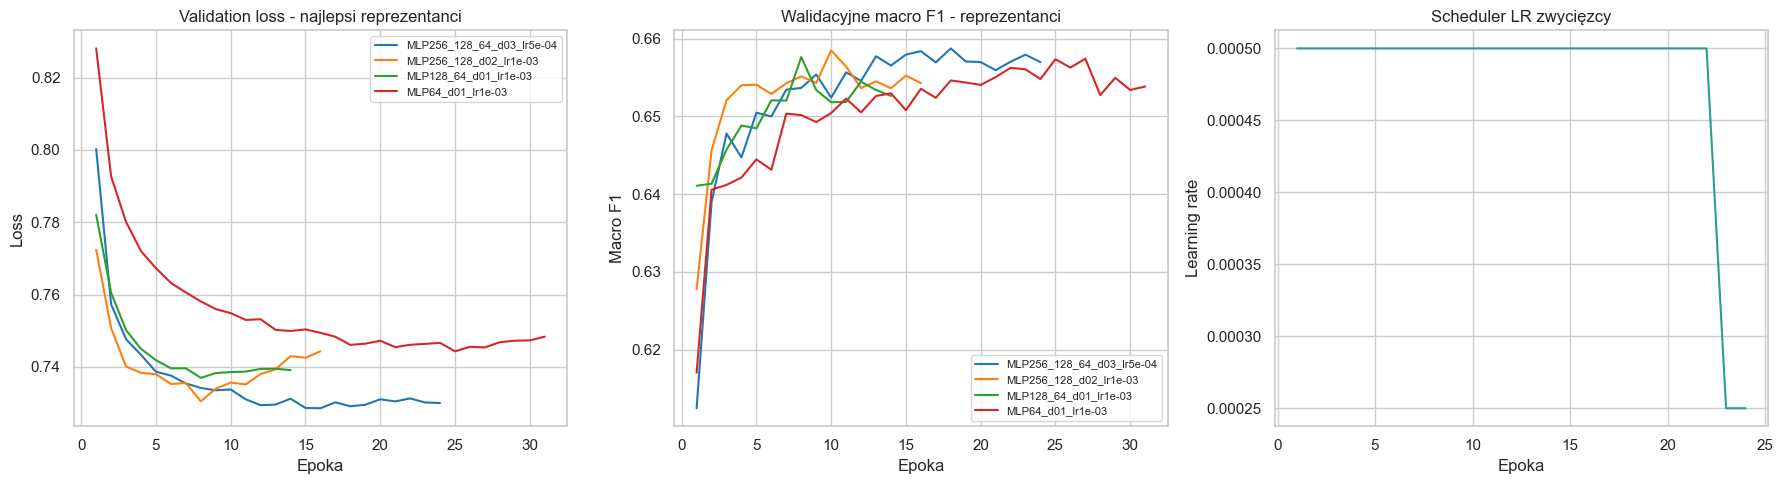

In [18]:
candidate_results["family"] = np.select(
    [
        candidate_results["config"].str.startswith("MLP64"),
        candidate_results["config"].str.startswith("MLP128"),
        candidate_results["config"].str.startswith("MLP256_128_64"),
        candidate_results["config"].str.startswith("MLP256_128"),
    ],
    ["64", "128_64", "256_128_64", "256_128"],
    default="other",
)
representatives = (
    candidate_results.sort_values("best_val_f1_macro", ascending=False)
    .groupby("family", sort=False)
    .head(1)
    .sort_values("best_val_f1_macro", ascending=False)
)
display(representatives[["family", "config", "dropout", "learning_rate", "epochs_run", "best_val_f1_macro"]].round(4))

palette = dict(zip(representatives["config"], sns.color_palette("tab10", len(representatives))))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for row in representatives.itertuples():
    history = candidate_histories[row.config]
    color = palette[row.config]
    axes[0].plot(history["epoch"], history["val_loss"], color=color, label=row.config)
    axes[1].plot(history["epoch"], history["val_f1_macro"], color=color, label=row.config)

axes[0].set_title("Validation loss - najlepsi reprezentanci")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[1].set_title("Walidacyjne macro F1 - reprezentanci")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Macro F1")
axes[1].legend(fontsize=8)

best_history_for_scheduler = candidate_histories[tuned_config_name]
axes[2].plot(best_history_for_scheduler["epoch"], best_history_for_scheduler["learning_rate"], color="#2a9d8f")
axes[2].set_title("Scheduler LR zwycięzcy")
axes[2].set_xlabel("Epoka")
axes[2].set_ylabel("Learning rate")
plt.tight_layout()
plt.show()


## 5. Modele referencyjne

Random Forest jest mocnym modelem porównawczym dla danych tabelarycznych. W ewaluacji dodajemy też proste modele `DummyClassifier`, żeby mieć punkt odniesienia dla pytania, czy MLP i RF faktycznie uczą się zależności, czy tylko korzystają z rozkładu klas.


In [19]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest trained.")


Random Forest trained.


### 5.1 Ważność cech według Random Forest

Ważność cech z RF jest dodatkowym, modelowym spojrzeniem na to, które atrybuty najbardziej pomagają w klasyfikacji. Nie zastępuje analizy korelacji, ale dobrze ją uzupełnia.


,feature,importance
11,num__Outstanding_Debt,0.0975
5,num__Interest_Rate,0.0705
7,num__Delay_from_due_date,0.0571
13,num__Credit_History_Age,0.0537
9,num__Changed_Credit_Limit,0.0536
16,num__Monthly_Balance,0.0434
15,num__Amount_invested_monthly,0.0415
12,num__Credit_Utilization_Ratio,0.0415
10,num__Num_Credit_Inquiries,0.0409
4,num__Num_Credit_Card,0.0391


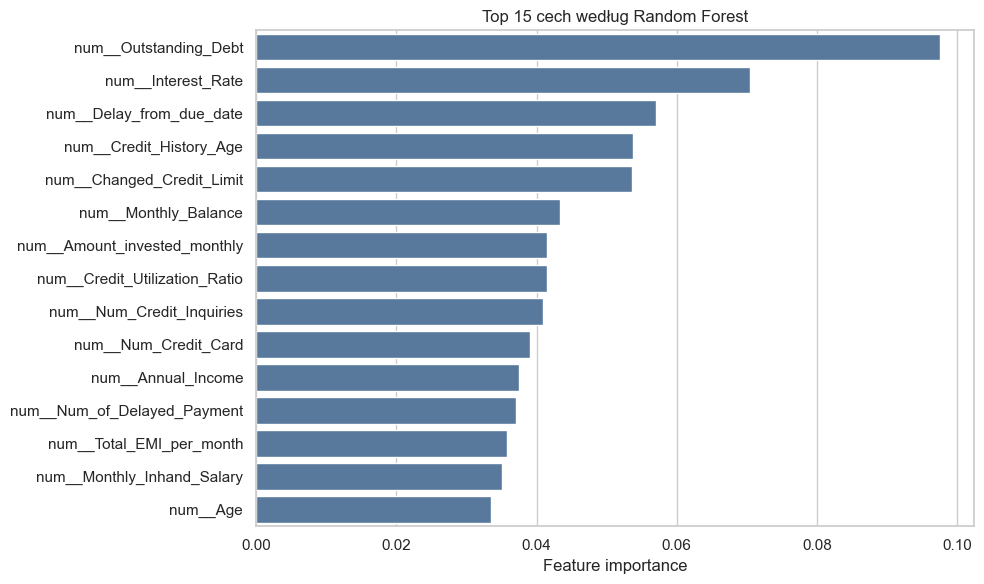

In [20]:
rf_feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_,
}).sort_values("importance", ascending=False)
display(rf_feature_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_feature_importance.head(15),
    x="importance",
    y="feature",
    color="#4c78a8",
)
plt.title("Top 15 cech według Random Forest")
plt.xlabel("Feature importance")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 6. Ewaluacja

Końcowe metryki liczymy wyłącznie na wydzielonym teście z `train.csv`. Test nie był używany do wyboru hiperparametrów ani do fitowania preprocessingu.


In [21]:
baseline_model = candidate_models[baseline_config_name]
tuned_model = candidate_models[tuned_config_name]
baseline_history = candidate_histories[baseline_config_name]
tuned_history = candidate_histories[tuned_config_name]

_, baseline_pred = predict_with_model(baseline_model, test_loader)
_, tuned_pred = predict_with_model(tuned_model, test_loader)

def metric_row(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

dummy_most_frequent = DummyClassifier(strategy="most_frequent")
dummy_stratified = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
dummy_most_frequent.fit(X_train, y_train)
dummy_stratified.fit(X_train, y_train)
dummy_most_frequent_pred = dummy_most_frequent.predict(X_test)
dummy_stratified_pred = dummy_stratified.predict(X_test)

comparison_table = pd.DataFrame([
    metric_row("Dummy most_frequent", y_test, dummy_most_frequent_pred),
    metric_row("Dummy stratified", y_test, dummy_stratified_pred),
    metric_row("Random Forest", y_test, rf_pred),
    metric_row(f"MLP baseline - {baseline_config_name}", y_test, baseline_pred),
    metric_row(f"MLP tuned - {tuned_config_name}", y_test, tuned_pred),
]).set_index("Model").sort_values("F1_macro", ascending=False)
comparison_table.round(4)


,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,
Random Forest,0.6893,0.6647,0.6595,0.6617
MLP baseline - MLP128_64_d02_lr1e-03,0.6584,0.6406,0.6903,0.6494
MLP tuned - MLP256_128_64_d03_lr5e-04,0.6568,0.6410,0.6938,0.6493
Dummy stratified,0.3962,0.3299,0.3299,0.3299
Dummy most_frequent,0.5319,0.1773,0.3333,0.2315


In [22]:
target_names = LABEL_ORDER
for model_name, predictions in [
    ("Dummy most_frequent", dummy_most_frequent_pred),
    ("Dummy stratified", dummy_stratified_pred),
    ("Random Forest", rf_pred),
    (f"MLP baseline - {baseline_config_name}", baseline_pred),
    (f"MLP tuned - {tuned_config_name}", tuned_pred),
]:
    print(f"\nClassification report - {model_name}")
    print(classification_report(y_test, predictions, target_names=target_names, zero_division=0))



Classification report - Dummy most_frequent
              precision    recall  f1-score   support

        Poor       0.00      0.00      0.00      4348
    Standard       0.53      1.00      0.69      7979
        Good       0.00      0.00      0.00      2673

    accuracy                           0.53     15000
   macro avg       0.18      0.33      0.23     15000
weighted avg       0.28      0.53      0.37     15000


Classification report - Dummy stratified
              precision    recall  f1-score   support

        Poor       0.29      0.29      0.29      4348
    Standard       0.53      0.53      0.53      7979
        Good       0.17      0.17      0.17      2673

    accuracy                           0.40     15000
   macro avg       0.33      0.33      0.33     15000
weighted avg       0.40      0.40      0.40     15000


Classification report - Random Forest
              precision    recall  f1-score   support

        Poor       0.71      0.65      0.68      4348
   

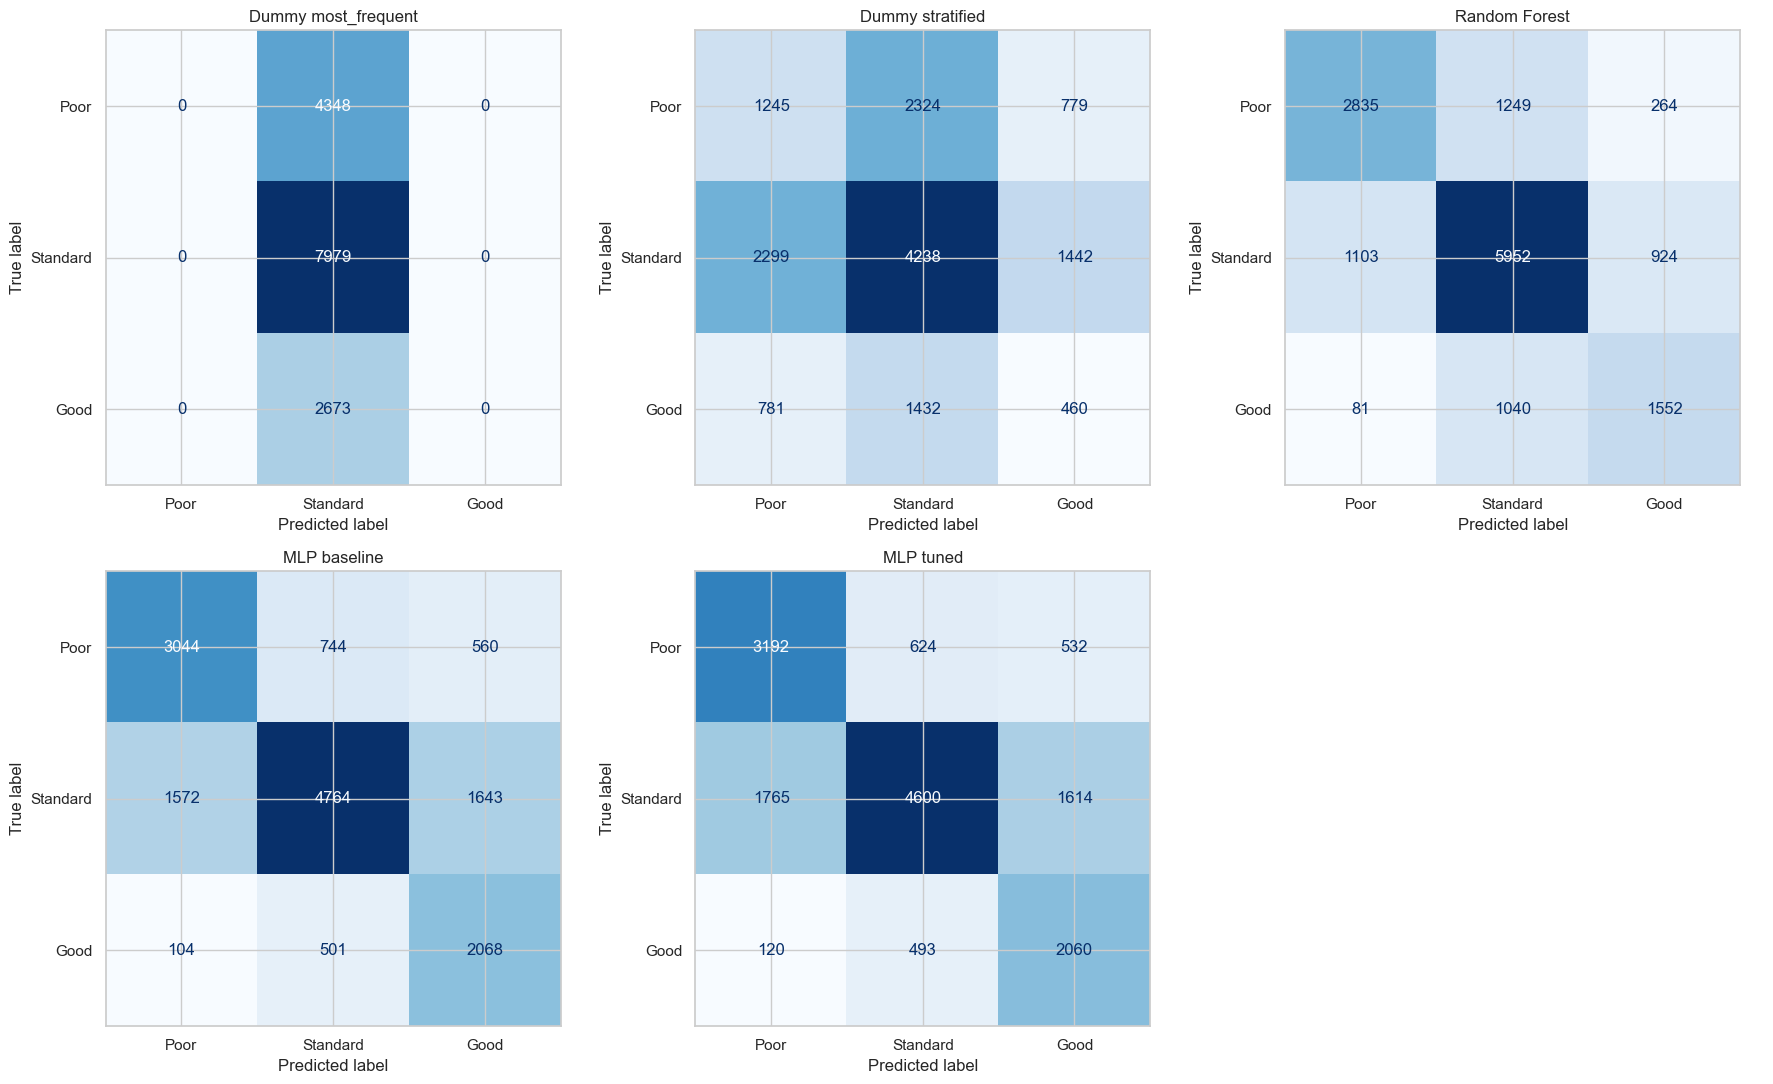

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()
for ax, title, predictions in [
    (axes[0], "Dummy most_frequent", dummy_most_frequent_pred),
    (axes[1], "Dummy stratified", dummy_stratified_pred),
    (axes[2], "Random Forest", rf_pred),
    (axes[3], "MLP baseline", baseline_pred),
    (axes[4], "MLP tuned", tuned_pred),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=list(range(len(LABEL_ORDER))),
        display_labels=LABEL_ORDER,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
axes[5].axis("off")
plt.tight_layout()
plt.show()


### 6.1 Najczęstsze pomyłki

Macierze pomyłek pokazują szczegóły wizualnie. Poniżej wypisujemy tylko najczęstszą pomyłkę dla RF i najlepszego MLP, żeby łatwiej przenieść tę interpretację do dokumentacji.


In [24]:
def print_most_common_confusion(model_name, y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=list(range(len(LABEL_ORDER))))
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    true_idx, pred_idx = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    count = off_diagonal[true_idx, pred_idx]
    print(
        f"{model_name}: najczęstsza pomyłka to {LABEL_ORDER[true_idx]} -> "
        f"{LABEL_ORDER[pred_idx]} ({count} rekordów)."
    )

print_most_common_confusion("Random Forest", y_test, rf_pred)
print_most_common_confusion("MLP tuned", y_test, tuned_pred)


Random Forest: najczęstsza pomyłka to Poor -> Standard (1249 rekordów).
MLP tuned: najczęstsza pomyłka to Standard -> Poor (1765 rekordów).


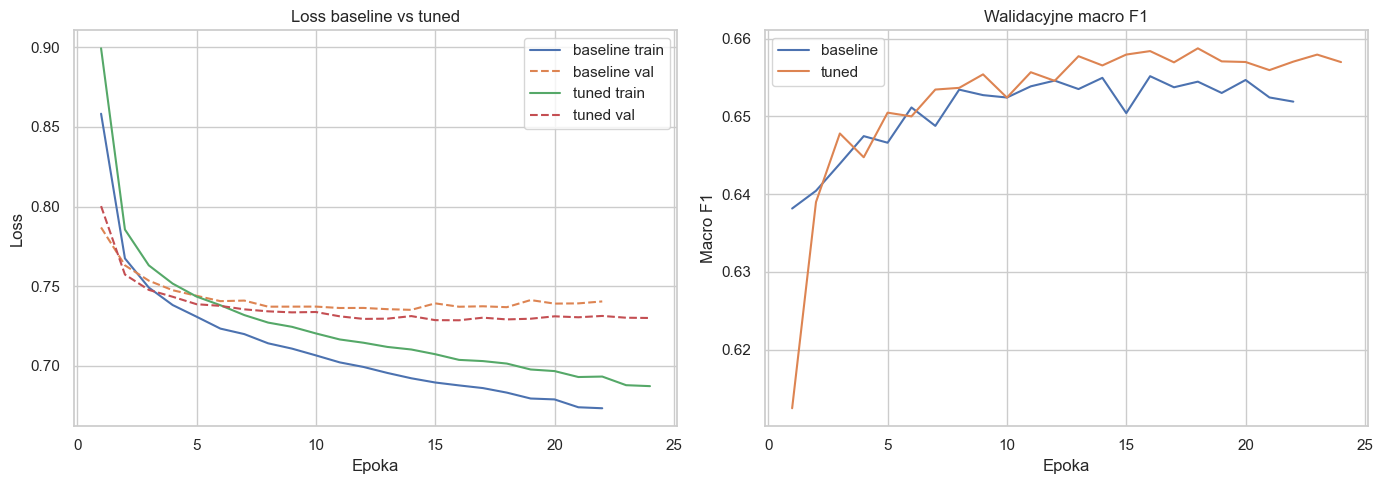

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in [("baseline", baseline_history), ("tuned", tuned_history)]:
    axes[0].plot(history["epoch"], history["train_loss"], label=f"{label} train")
    axes[0].plot(history["epoch"], history["val_loss"], linestyle="--", label=f"{label} val")
    axes[1].plot(history["epoch"], history["val_f1_macro"], label=label)

axes[0].set_title("Loss baseline vs tuned")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].set_title("Walidacyjne macro F1")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Predykcja dla kagglowego `test.csv`

Poniżej używamy najlepszego modelu MLP do wygenerowania predykcji dla `test.csv`. Nie liczymy tutaj metryk, ponieważ ten plik nie zawiera prawdziwych etykiet. Dla sanity check porównujemy rozkład przewidzianych klas z rozkładem klas w oznaczonym `train.csv`.


In [26]:
kaggle_test_loader = DataLoader(
    TensorDataset(torch.tensor(X_kaggle_test, dtype=torch.float32)),
    batch_size=2048,
    shuffle=False,
    pin_memory=(device.type == "cuda"),
)

def predict_unlabeled(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for (features,) in loader:
            features = features.to(device, non_blocking=True)
            logits = model(features)
            predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return np.array(predictions)

kaggle_test_pred_ids = predict_unlabeled(tuned_model, kaggle_test_loader)
kaggle_test_pred_labels = pd.Series(kaggle_test_pred_ids).map(ID_TO_LABEL)

prediction_output = pd.DataFrame({
    "ID": kaggle_test[ID_COL],
    "Predicted_Credit_Score": kaggle_test_pred_labels,
})
prediction_output.to_csv(PREDICTION_OUTPUT_PATH, index=False)
assert len(prediction_output) == len(kaggle_test)

train_distribution = raw_train[TARGET_COL].value_counts(normalize=True).reindex(LABEL_ORDER) * 100
pred_distribution = prediction_output["Predicted_Credit_Score"].value_counts(normalize=True).reindex(LABEL_ORDER) * 100
prediction_distribution = pd.DataFrame({
    "train_true_percent": train_distribution.round(2),
    "kaggle_test_predicted_percent": pred_distribution.round(2),
})
print(f"Saved predictions to: {PREDICTION_OUTPUT_PATH.resolve()}")
display(prediction_output.head())
prediction_distribution


Saved predictions to: C:\Users\piotr\Desktop\Bartman SI\Projekt 2\credit_score_test_predictions.csv


,ID,Predicted_Credit_Score
0,0x160a,Good
1,0x160b,Good
2,0x160c,Good
3,0x160d,Good
4,0x1616,Good


,train_true_percent,kaggle_test_predicted_percent
Poor,29.00,34.56
Standard,53.17,36.69
Good,17.83,28.75


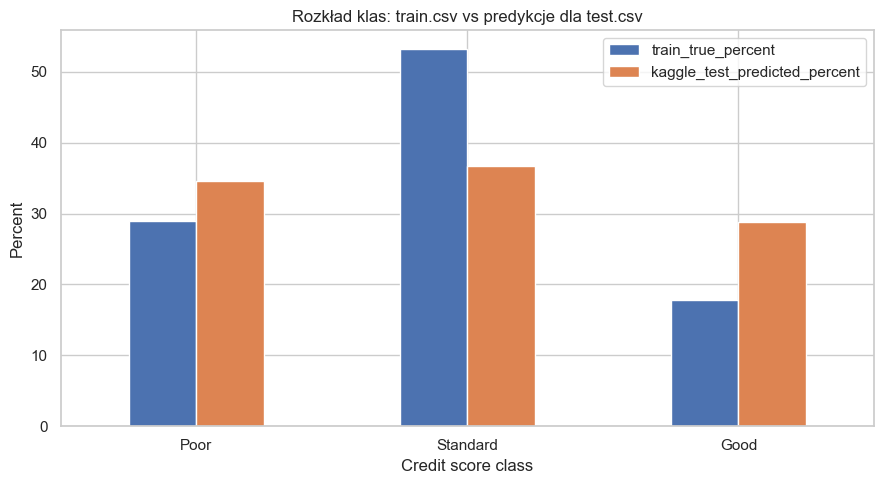

In [27]:
prediction_distribution.plot(kind="bar", figsize=(9, 5))
plt.title("Rozkład klas: train.csv vs predykcje dla test.csv")
plt.ylabel("Percent")
plt.xlabel("Credit score class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Wnioski

Eksperyment potwierdził, że zbiór `Credit Score Classification` spełnia wymagania projektu: jest to klasyfikacja wieloklasowa z trzema klasami (`Poor`, `Standard`, `Good`) i zawiera kilka rzeczywistych atrybutów kategorycznych wymagających kodowania. W finalnym preprocessingu użyto one-hot encoding dla `Occupation`, `Credit_Mix`, `Payment_of_Min_Amount` i `Payment_Behaviour` oraz multi-hot encoding dla wielowartościowego `Type_of_Loan`. Po transformacji model dostał `54` cechy: `17` numerycznych, `27` cech one-hot i `10` cech multi-hot.

Eksploracja danych pokazała, że preprocessing jest rzeczywiście potrzebny, a nie dopisany „na siłę”. W surowych danych występują tekstowe artefakty i tokeny techniczne, np. `_` w `Changed_Credit_Limit` (`2.09%`), `_` w `Credit_Mix` (`20.20%`), `_______` w `Occupation` (`7.06%`) oraz `!@9#%8` w `Payment_Behaviour` (`7.60%`). Po czyszczeniu i zamianie wartości nierealnych na `NaN` najwięcej braków miały `Credit_Mix` (`20.07%`), `Monthly_Inhand_Salary` (`14.91%`), `Type_of_Loan` (`11.30%`), `Credit_History_Age` (`9.06%`) i `Age` (`8.70%`). Aż `69.17%` rekordów treningowych miało przynajmniej jeden brak po czyszczeniu, więc masowe usuwanie rekordów byłoby zbyt kosztowne. Dlatego zastosowano imputację medianą dla cech numerycznych i modą dla kategorycznych, fitowaną wyłącznie na train.

Odrzucanie wartości skrajnych zostało wykonane przez progi domenowe, a IQR potraktowano jako diagnostykę. Progi domenowe realnie zadziałały, np. ustawiły na `NaN` `6093` wartości w `Age`, `3026` w `Num_of_Loan`, `1574` w `Num_Credit_Card`, `1413` w `Interest_Rate` i `1155` w `Num_Credit_Inquiries`. IQR często flagował wartości, które w finansach mogą być wysokie, ale nadal realistyczne, np. `Amount_invested_monthly`, `Monthly_Balance` czy `Outstanding_Debt`, dlatego nie zastąpił reguł domenowych w finalnym pipeline.

Analiza zależności z targetem potwierdziła sens biznesowy cech. Najsilniejsze cechy numeryczne według `f_classif` to m.in. `Interest_Rate`, `Delay_from_due_date`, `Num_Credit_Inquiries`, `Num_Credit_Card`, `Num_Bank_Accounts`, `Outstanding_Debt` i `Credit_History_Age`. Dla kategorii najwyższy związek z targetem miały `Credit_Mix` (`Cramér's V = 0.3905`) oraz `Payment_of_Min_Amount` (`0.3161`). Ważności cech z Random Forest również wskazały głównie atrybuty finansowe i behawioralne: `Outstanding_Debt`, `Interest_Rate`, `Delay_from_due_date`, `Credit_History_Age` i `Changed_Credit_Limit`.

Podział danych został wykonany grupowo po `Customer_ID`, dzięki czemu miesiące tego samego klienta nie trafiły jednocześnie do train, validation i test. To ważne, ponieważ w zbiorze jest `12 500` klientów, a każdy występuje dokładnie `8` razy. Wynik nie jest więc podejrzanie zawyżony: model był testowany na klientach, których nie widział podczas treningu. Przy zwykłym losowym podziale po wierszach wyniki prawdopodobnie byłyby wyższe, ale mogłyby wynikać z wycieku danych między miesiącami tego samego klienta.

Test wariantu kodowania `Credit_Mix` pokazał, że porządkowe kodowanie `Bad=0`, `Standard=1`, `Good=2` dla Random Forest dało na walidacji `accuracy = 0.6910` i `macro F1 = 0.6653`, a OHE `accuracy = 0.6897` i `macro F1 = 0.6633`. Różnica jest minimalna, więc finalny pipeline zostaje przy OHE: liczba cech po kodowaniu jest nadal mała, a OHE nie narzuca sztucznego porządku pozostałym kategoriom. W dokumentacji można jednak wspomnieć, że dla samego `Credit_Mix` wariant ordinal jest również metodycznie uzasadniony.

Najlepszym wariantem MLP na walidacji był `MLP256_128_64_d03_lr5e-04`, czyli sieć z trzema warstwami ukrytymi `(256, 128, 64)`, dropoutem `0.30` i learning rate `5e-04`. Uzyskała walidacyjne `macro F1 = 0.6587`. Mała sieć `MLP64_d01_lr1e-03` uzyskała jednak `macro F1 = 0.6573`, więc różnica wyniosła tylko `0.0014`. To potwierdza uwagę prowadzącego: większa sieć nie daje realnej przewagi na tym problemie i prawdopodobnie nie jest konieczna. Na zbiorze testowym tuned MLP osiągnął `accuracy = 0.6568` i `macro F1 = 0.6493`, czyli praktycznie tyle samo co baseline `MLP128_64_d02_lr1e-03` (`accuracy = 0.6584`, `macro F1 = 0.6494`).

Najlepszym modelem w końcowym porównaniu okazał się Random Forest: `accuracy = 0.6893` i `macro F1 = 0.6617`. MLP nadal jest poprawnie zbudowaną siecią neuronową i spełnia założenia projektu, ale dla tych danych tabelarycznych domyślny Random Forest poradził sobie lepiej. To sensowny wynik, bo modele drzewiaste często są mocne na danych tabelarycznych z relacjami progowymi, kategoriami i nieliniowościami.

Wyniki nie są bliskie losowemu zgadywaniu. `DummyClassifier(strategy="most_frequent")`, który zawsze wybiera najczęstszą klasę `Standard`, osiągnął `accuracy = 0.5319`, ale tylko `macro F1 = 0.2315`, bo całkowicie ignoruje klasy `Poor` i `Good`. `DummyClassifier(strategy="stratified")` uzyskał `accuracy = 0.3962` i `macro F1 = 0.3299`. Na tym tle MLP (`macro F1 = 0.6493`) i Random Forest (`macro F1 = 0.6617`) są wyraźnie lepsze od prostych strategii bazowych.

Macierze pomyłek pokazują różne zachowanie modeli. Najczęstsza pomyłka Random Forest to `Poor -> Standard` (`1249` rekordów), a najczęstsza pomyłka tuned MLP to `Standard -> Poor` (`1765` rekordów). MLP mocno korzysta z wag klas: lepiej wyciąga klasy mniejszościowe (`Good` i `Poor`), ale częściej przesuwa przypadki klasy `Standard` do klas skrajnych. Random Forest jest bardziej zrównoważony, co przełożyło się na wyższe końcowe macro F1.

Dla kagglowego `test.csv` wygenerowano plik `credit_score_test_predictions.csv` z kolumnami `ID` i `Predicted_Credit_Score`. Predykcje wykonano modelem MLP tuned, ponieważ MLP jest głównym modelem projektu. Gdyby celem była wyłącznie maksymalizacja trafności predykcji, lepszym kandydatem byłby Random Forest. Na `test.csv` nie liczono metryk, bo plik nie zawiera prawdziwego `Credit_Score`. Rozkład predykcji różni się od rozkładu klas w oznaczonym `train.csv`: w train jest około `53.17%` klasy `Standard`, a w predykcjach dla `test.csv` tylko `36.69%`; jednocześnie model przewiduje więcej `Poor` (`34.56%`) i `Good` (`28.75%`). To pasuje do zachowania MLP widocznego w raporcie testowym, gdzie model część przypadków `Standard` przesuwa do klas skrajnych.

Główne ograniczenia projektu to korelacja miesięcy tego samego klienta w obrębie zbioru uczącego, ręcznie dobrane progi dla wartości nierealnych, pozostawienie OHE jako finalnego kodowania mimo minimalnie lepszego testu ordinal dla `Credit_Mix` oraz brak etykiet dla kagglowego `test.csv`. Mimo tego protokół ewaluacji jest uczciwy: preprocessing był fitowany tylko na train, test metryczny nie był używany do tuningu, a group split ograniczył najważniejsze ryzyko wycieku danych.
